# Advanced NLP Project – DistilBERT Language Model

## Internship: ShadowFox AI/ML Engineer Internship

### Objective
To implement and demonstrate a pretrained DistilBERT language model for sentiment analysis using Python and Hugging Face Transformers.

### Project Description
This project uses DistilBERT, a lightweight transformer-based language model, to analyze text and identify its sentiment. The model will be tested with different text inputs, and its performance, capabilities, parameters, and limitations will be studied.

### Tools and Technologies
- Python
- Google Colab
- Hugging Face Transformers
- PyTorch
- DistilBERT
- Gradio

### Expected Outcome
An interactive sentiment analysis system that predicts the sentiment of user-provided text.

*   List item

1.   List item
2.   List item


*   List item



In [15]:
!pip install transformers torch gradio

In [16]:
from transformers import pipeline

sentiment_pipeline = pipeline(
    "sentiment-analysis",
    model="distilbert/distilbert-base-uncased-finetuned-sst-2-english"
)

print("DistilBERT model loaded successfully!")

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

DistilBERT model loaded successfully!


In [17]:
text = "I really enjoyed learning artificial intelligence."

result = sentiment_pipeline(text)

print("Input:", text)
print("Prediction:", result)

Input: I really enjoyed learning artificial intelligence.
Prediction: [{'label': 'POSITIVE', 'score': 0.9997187256813049}]


In [18]:
text = "This movie was boring and disappointing."

result = sentiment_pipeline(text)

print("Input:", text)
print("Prediction:", result)

Input: This movie was boring and disappointing.
Prediction: [{'label': 'NEGATIVE', 'score': 0.9997838139533997}]


In [19]:
from transformers import AutoTokenizer

model_name = "distilbert/distilbert-base-uncased-finetuned-sst-2-english"

tokenizer = AutoTokenizer.from_pretrained(model_name)

print("Tokenizer loaded successfully!")

Tokenizer loaded successfully!


In [20]:
text = "I love learning artificial intelligence."

tokens = tokenizer.tokenize(text)

print("Original text:", text)
print("Tokens:", tokens)

Original text: I love learning artificial intelligence.
Tokens: ['i', 'love', 'learning', 'artificial', 'intelligence', '.']


In [21]:
token_ids = tokenizer.convert_tokens_to_ids(tokens)

print("Tokens:", tokens)
print("Token IDs:", token_ids)

Tokens: ['i', 'love', 'learning', 'artificial', 'intelligence', '.']
Token IDs: [1045, 2293, 4083, 7976, 4454, 1012]


In [22]:
encoded = tokenizer(text, return_tensors="pt")

print("Input IDs:", encoded["input_ids"])
print("Attention Mask:", encoded["attention_mask"])

Input IDs: tensor([[ 101, 1045, 2293, 4083, 7976, 4454, 1012,  102]])
Attention Mask: tensor([[1, 1, 1, 1, 1, 1, 1, 1]])


In [23]:
test_sentences = [
    "This product is amazing!",
    "I hate this experience.",
    "The movie was okay, nothing special.",
    "The food was not good.",
    "I am extremely happy today!"
]

for sentence in test_sentences:
    result = sentiment_pipeline(sentence)

    print("Text:", sentence)
    print("Sentiment:", result[0]["label"])
    print("Confidence:", round(result[0]["score"] * 100, 2), "%")
    print("-" * 50)

Text: This product is amazing!
Sentiment: POSITIVE
Confidence: 99.99 %
--------------------------------------------------
Text: I hate this experience.
Sentiment: NEGATIVE
Confidence: 99.96 %
--------------------------------------------------
Text: The movie was okay, nothing special.
Sentiment: NEGATIVE
Confidence: 99.25 %
--------------------------------------------------
Text: The food was not good.
Sentiment: NEGATIVE
Confidence: 99.97 %
--------------------------------------------------
Text: I am extremely happy today!
Sentiment: POSITIVE
Confidence: 99.99 %
--------------------------------------------------


In [24]:
challenging_sentences = [
    "I expected better from this product.",
    "The service was not bad.",
    "I am happy, but the experience was disappointing.",
    "Yeah, that was just wonderful... NOT!",
    "The movie was neither good nor bad.",
    "I don't think this is a terrible product."
]

for sentence in challenging_sentences:
    result = sentiment_pipeline(sentence)

    print("Text:", sentence)
    print("Prediction:", result[0]["label"])
    print("Confidence:", round(result[0]["score"] * 100, 2), "%")
    print("-" * 60)

Text: I expected better from this product.
Prediction: NEGATIVE
Confidence: 99.85 %
------------------------------------------------------------
Text: The service was not bad.
Prediction: POSITIVE
Confidence: 99.71 %
------------------------------------------------------------
Text: I am happy, but the experience was disappointing.
Prediction: NEGATIVE
Confidence: 99.33 %
------------------------------------------------------------
Text: Yeah, that was just wonderful... NOT!
Prediction: POSITIVE
Confidence: 99.95 %
------------------------------------------------------------
Text: The movie was neither good nor bad.
Prediction: NEGATIVE
Confidence: 99.38 %
------------------------------------------------------------
Text: I don't think this is a terrible product.
Prediction: POSITIVE
Confidence: 96.48 %
------------------------------------------------------------


In [25]:
!pip install gradio

In [26]:
def analyze_sentiment(text):
    result = sentiment_pipeline(text)[0]

    sentiment = result["label"]
    confidence = result["score"] * 100

    return f"""
    Sentiment: {sentiment}
    Confidence: {confidence:.2f}%
    """

In [27]:
import gradio as gr

demo = gr.Interface(
    fn=analyze_sentiment,
    inputs=gr.Textbox(
        lines=3,
        placeholder="Enter a sentence here..."
    ),
    outputs="text",
    title="DistilBERT Sentiment Analyzer",
    description="An AI-powered sentiment analysis application"
)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://4c0817697e5248c6c5.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [28]:
import pandas as pd

test_data = [
    "I absolutely love this product!",
    "This is the worst experience ever.",
    "The service was not bad.",
    "I am not happy with the results.",
    "The product is average."
]

results = []

for sentence in test_data:
    prediction = sentiment_pipeline(sentence)[0]

    results.append({
        "Input Text": sentence,
        "Predicted Sentiment": prediction["label"],
        "Confidence": round(prediction["score"] * 100, 2)
    })

results_df = pd.DataFrame(results)

display(results_df)

results_df.to_csv("distilbert_test_results.csv", index=False)

,Input Text,Predicted Sentiment,Confidence
0,I absolutely love this product!,POSITIVE,99.99
1,This is the worst experience ever.,NEGATIVE,99.98
2,The service was not bad.,POSITIVE,99.71
3,I am not happy with the results.,NEGATIVE,99.98
4,The product is average.,NEGATIVE,98.50


In [29]:
from google.colab import files

files.download("distilbert_test_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [30]:
config = sentiment_pipeline.model.config

print("Model Name:", config.name_or_path)
print("Number of Transformer Layers:", config.n_layers)
print("Attention Heads:", config.n_heads)
print("Hidden Size:", config.dim)
print("Vocabulary Size:", config.vocab_size)
print("Number of Labels:", config.num_labels)
print("Labels:", config.id2label)

Model Name: distilbert/distilbert-base-uncased-finetuned-sst-2-english
Number of Transformer Layers: 6
Attention Heads: 12
Hidden Size: 768
Vocabulary Size: 30522
Number of Labels: 2
Labels: {0: 'NEGATIVE', 1: 'POSITIVE'}


In [31]:
total_parameters = sum(
    parameter.numel()
    for parameter in sentiment_pipeline.model.parameters()
)

trainable_parameters = sum(
    parameter.numel()
    for parameter in sentiment_pipeline.model.parameters()
    if parameter.requires_grad
)

print("Total Parameters:", total_parameters)
print("Trainable Parameters:", trainable_parameters)

Total Parameters: 66955010
Trainable Parameters: 66955010


## DistilBERT Model Architecture

DistilBERT is a smaller and faster version of BERT. It uses a Transformer-based encoder architecture to understand the context of text.

### Main Components

1. **Tokenization:** Converts input text into tokens and numerical IDs.
2. **Embedding Layer:** Converts tokens into vector representations.
3. **Transformer Encoder:** Processes the input using self-attention and feed-forward neural network layers.
4. **Classification Layer:** Predicts the sentiment of the input text.
5. **Output:** Produces a positive or negative sentiment label with a confidence score.

### Important Model Parameters

- Number of Transformer Layers
- Number of Attention Heads
- Hidden Size
- Vocabulary Size
- Number of Classification Labels

### Observation

The selected pretrained DistilBERT model is designed for binary sentiment classification. It can identify positive and negative text, but it may struggle with sarcasm and neutral expressions.

## Model Configuration and Parameter Analysis

The selected DistilBERT model has the following configuration:

- Model: DistilBERT fine-tuned on SST-2
- Transformer Layers: 6
- Attention Heads: 12
- Hidden Size: 768
- Vocabulary Size: 30,522
- Classification Labels: 2 (Positive and Negative)

### Parameter Analysis

- Total Parameters: 66,955,010
- Trainable Parameters: 66,955,010

### Observation

The model contains approximately 66.96 million parameters. It uses six Transformer encoder layers and twelve attention heads to process text. The selected model is pretrained and fine-tuned for binary sentiment classification.

Although its parameters are marked as trainable, this project uses the model for prediction without updating its weights.

In [32]:
test_sentences = [
    "I absolutely love this product!",
    "This is the worst experience ever.",
    "The service was not bad.",
    "I am not happy with the results.",
    "The food was delicious.",
    "The customer support was terrible.",
    "I really enjoyed this movie.",
    "I hate waiting for so long.",
    "This is an excellent experience.",
    "I am very disappointed with this purchase."
]

# Actual sentiment labels (ground truth)
actual_labels = [
    "POSITIVE",
    "NEGATIVE",
    "POSITIVE",
    "NEGATIVE",
    "POSITIVE",
    "NEGATIVE",
    "POSITIVE",
    "NEGATIVE",
    "POSITIVE",
    "NEGATIVE"
]

print("Test dataset prepared successfully!")
print("Total sentences:", len(test_sentences))

Test dataset prepared successfully!
Total sentences: 10


In [33]:
predicted_labels = []

for sentence in test_sentences:
    result = sentiment_pipeline(sentence)[0]
    predicted_labels.append(result["label"])

print("Predictions completed!")

for i in range(len(test_sentences)):
    print("Text:", test_sentences[i])
    print("Actual:", actual_labels[i])
    print("Predicted:", predicted_labels[i])
    print("-" * 50)

Predictions completed!
Text: I absolutely love this product!
Actual: POSITIVE
Predicted: POSITIVE
--------------------------------------------------
Text: This is the worst experience ever.
Actual: NEGATIVE
Predicted: NEGATIVE
--------------------------------------------------
Text: The service was not bad.
Actual: POSITIVE
Predicted: POSITIVE
--------------------------------------------------
Text: I am not happy with the results.
Actual: NEGATIVE
Predicted: NEGATIVE
--------------------------------------------------
Text: The food was delicious.
Actual: POSITIVE
Predicted: POSITIVE
--------------------------------------------------
Text: The customer support was terrible.
Actual: NEGATIVE
Predicted: NEGATIVE
--------------------------------------------------
Text: I really enjoyed this movie.
Actual: POSITIVE
Predicted: POSITIVE
--------------------------------------------------
Text: I hate waiting for so long.
Actual: NEGATIVE
Predicted: NEGATIVE
-----------------------------------

In [34]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

accuracy = accuracy_score(actual_labels, predicted_labels)

precision = precision_score(
    actual_labels, predicted_labels,
    pos_label="POSITIVE"
)

recall = recall_score(
    actual_labels, predicted_labels,
    pos_label="POSITIVE"
)

f1 = f1_score(
    actual_labels, predicted_labels,
    pos_label="POSITIVE"
)

print("Accuracy:", round(accuracy * 100, 2), "%")
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1 Score:", round(f1, 4))

print("\nClassification Report:")
print(classification_report(actual_labels, predicted_labels))

Accuracy: 100.0 %
Precision: 1.0
Recall: 1.0
F1 Score: 1.0

Classification Report:
              precision    recall  f1-score   support

    NEGATIVE       1.00      1.00      1.00         5
    POSITIVE       1.00      1.00      1.00         5

    accuracy                           1.00        10
   macro avg       1.00      1.00      1.00        10
weighted avg       1.00      1.00      1.00        10



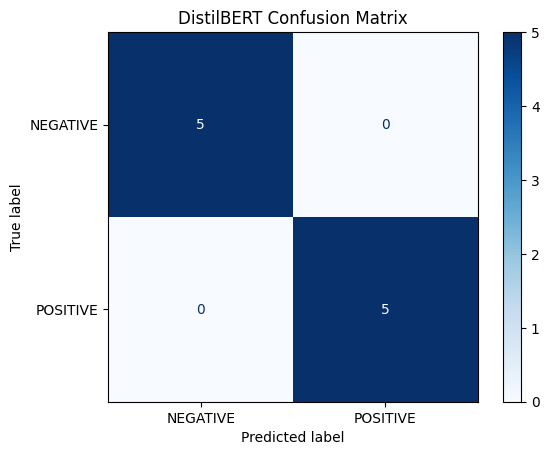

In [35]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(
    actual_labels,
    predicted_labels,
    labels=["NEGATIVE", "POSITIVE"]
)

display_matrix = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["NEGATIVE", "POSITIVE"]
)

display_matrix.plot(cmap="Blues")
plt.title("DistilBERT Confusion Matrix")
plt.show()

In [36]:
import pandas as pd

performance = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1 Score"],
    "Score": [accuracy, precision, recall, f1]
})

performance.to_csv(
    "distilbert_performance_metrics.csv",
    index=False
)

print("Performance metrics saved successfully!")

Performance metrics saved successfully!


In [37]:
from google.colab import files

files.download("distilbert_performance_metrics.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Performance Evaluation

The DistilBERT model was evaluated using a test dataset containing 10 sentences with known sentiment labels.

The following evaluation metrics were calculated:

1. **Accuracy:** Measures the overall percentage of correct predictions.
2. **Precision:** Measures how many predicted positive sentences were actually positive.
3. **Recall:** Measures how many actual positive sentences were correctly identified.
4. **F1-score:** Combines precision and recall into a single score.
5. **Confusion Matrix:** Shows correct and incorrect predictions for both sentiment classes.

### Observation

The evaluation results help understand the classification performance of the pretrained DistilBERT model. The confusion matrix helps identify prediction errors and the classification report provides detailed performance measurements.

The results are based on a small demonstration dataset and should not be considered a general benchmark of the model.

## Day 9 – Performance Evaluation Results

The DistilBERT sentiment analysis model was evaluated using 10 test sentences, including 5 positive and 5 negative sentences.

### Evaluation Metrics

| Metric | Result |
|---|---:|
| Accuracy | 100% |
| Precision | 1.00 |
| Recall | 1.00 |
| F1-score | 1.00 |

### Confusion Matrix Analysis

- True Negative: 5
- True Positive: 5
- False Positive: 0
- False Negative: 0

### Result and Observation

The model correctly classified all 10 test sentences and achieved 100% accuracy on this demonstration dataset.

However, this is a small test dataset with straightforward examples. It does not establish that the model will achieve 100% accuracy on unseen real-world data. Further testing with larger and more diverse datasets is required.

In [38]:
custom_sentences = [
    "The laptop performance is excellent.",
    "I am unhappy with this service.",
    "The product is worth buying.",
    "I regret purchasing this item.",
    "The experience was wonderful.",
    "The quality is disappointing."
]

for sentence in custom_sentences:
    result = sentiment_pipeline(sentence)[0]

    print("Input:", sentence)
    print("Sentiment:", result["label"])
    print("Confidence:", round(result["score"] * 100, 2), "%")
    print("-" * 50)

Input: The laptop performance is excellent.
Sentiment: POSITIVE
Confidence: 99.98 %
--------------------------------------------------
Input: I am unhappy with this service.
Sentiment: NEGATIVE
Confidence: 99.97 %
--------------------------------------------------
Input: The product is worth buying.
Sentiment: POSITIVE
Confidence: 99.99 %
--------------------------------------------------
Input: I regret purchasing this item.
Sentiment: NEGATIVE
Confidence: 99.87 %
--------------------------------------------------
Input: The experience was wonderful.
Sentiment: POSITIVE
Confidence: 99.99 %
--------------------------------------------------
Input: The quality is disappointing.
Sentiment: NEGATIVE
Confidence: 99.98 %
--------------------------------------------------


In [39]:
my_sentence = input("Enter your sentence: ")

result = sentiment_pipeline(my_sentence)[0]

print("\nPredicted Sentiment:", result["label"])
print("Confidence:", round(result["score"] * 100, 2), "%")

Enter your sentence: I am excited about my AI internship.

Predicted Sentiment: POSITIVE
Confidence: 99.91 %


In [40]:
import pandas as pd

custom_results = []

for sentence in custom_sentences:
    result = sentiment_pipeline(sentence)[0]

    custom_results.append({
        "Input Text": sentence,
        "Sentiment": result["label"],
        "Confidence": round(result["score"] * 100, 2)
    })

custom_df = pd.DataFrame(custom_results)

display(custom_df)

custom_df.to_csv("distilbert_custom_test_results.csv", index=False)

print("Custom results saved successfully!")

,Input Text,Sentiment,Confidence
0,The laptop performance is excellent.,POSITIVE,99.98
1,I am unhappy with this service.,NEGATIVE,99.97
2,The product is worth buying.,POSITIVE,99.99
3,I regret purchasing this item.,NEGATIVE,99.87
4,The experience was wonderful.,POSITIVE,99.99
5,The quality is disappointing.,NEGATIVE,99.98


Custom results saved successfully!


In [41]:
from google.colab import files

files.download("distilbert_custom_test_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Day 10 – Custom Input Testing

The DistilBERT sentiment analysis model was tested using custom sentences created by the developer.

The model accepts user-provided text and predicts whether the sentiment is positive or negative.

For each input, the model displays:
- Original input sentence
- Predicted sentiment
- Confidence score

### Observation

The custom testing process demonstrates that the pretrained DistilBERT model can classify different user-provided sentences. The results also help examine its behavior on different expressions and writing styles.

In [42]:
import pandas as pd

custom_results = []

for sentence in custom_sentences:
    result = sentiment_pipeline(sentence)[0]

    custom_results.append({
        "Input Text": sentence,
        "Sentiment": result["label"],
        "Confidence": round(result["score"] * 100, 2)
    })

custom_df = pd.DataFrame(custom_results)

display(custom_df)

custom_df.to_csv("distilbert_custom_test_results.csv", index=False)

print("Custom results saved successfully!")

,Input Text,Sentiment,Confidence
0,The laptop performance is excellent.,POSITIVE,99.98
1,I am unhappy with this service.,NEGATIVE,99.97
2,The product is worth buying.,POSITIVE,99.99
3,I regret purchasing this item.,NEGATIVE,99.87
4,The experience was wonderful.,POSITIVE,99.99
5,The quality is disappointing.,NEGATIVE,99.98


Custom results saved successfully!


In [43]:
from google.colab import files
files.download("distilbert_custom_test_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

 Custom Input Testing

The DistilBERT sentiment analysis model was tested using custom sentences created by the developer.

The model accepts user-provided text and predicts whether the sentiment is positive or negative.

For each input, the model displays:
- Original input sentence
- Predicted sentiment
- Confidence score

### Observation

The custom testing process demonstrates that the pretrained DistilBERT model can classify different user-provided sentences. The results also help examine its behavior on different expressions and writing styles.

 Strengths and Limitations of DistilBERT

### Strengths

1. Lightweight Model: DistilBERT is smaller and faster than BERT.
2. Fast Prediction: It can classify text quickly.
3. Easy to Use: It can be implemented using the Hugging Face Transformers library.
4. Good Performance: It produces accurate sentiment predictions on many clear positive and negative sentences.
5. User-Friendly: It can be integrated into applications using Gradio.

### Limitations

1. Binary Classification: The selected model predicts only positive or negative sentiment.
2. Sarcasm Detection: It may misunderstand sarcastic sentences.
3. Mixed Sentiments: It may struggle when a sentence contains both positive and negative opinions.
4. Context Understanding: It may not fully understand complex language or context.
5. Confidence Scores: A high confidence score does not always mean that a prediction is correct.

### Conclusion

DistilBERT is a lightweight and useful language model for sentiment analysis. However, it has limitations when handling sarcasm, neutral expressions, and mixed opinions. It should be evaluated carefully before being used in real-world applications.

##  Ethical Considerations of DistilBERT

### 1. Bias in Predictions
The model may produce biased predictions because it learns from its training data. It may not interpret every person's language in the same way.

### 2. Privacy
User-provided text may contain personal or confidential information. Such information should be handled carefully and should not be shared without permission.

### 3. Incorrect Predictions
The model can sometimes misunderstand sarcasm, mixed emotions, or complex sentences. Its predictions should not always be treated as correct.

### 4. Transparency
Users should be informed that their text is being analyzed by an AI model. The model's predictions and limitations should be clearly explained.

### 5. Responsible Usage
Sentiment predictions should not be the only basis for important decisions about people. Human judgment should be included when necessary.

### Conclusion
DistilBERT is useful for sentiment analysis, but it must be used responsibly. Developers should consider bias, privacy, accuracy, and transparency to ensure ethical AI applications.

##  Final Project Conclusion

### Project Summary

In this project, a pretrained DistilBERT language model was implemented for sentiment analysis using Python and the Hugging Face Transformers library.

The model was used to classify text into two sentiment categories: POSITIVE and NEGATIVE.

### Work Completed

1. Loaded the pretrained DistilBERT model.
2. Explored tokenization and attention masks.
3. Tested the model with different text inputs.
4. Evaluated challenging sentences to identify model limitations.
5. Developed an interactive sentiment analysis application using Gradio.
6. Saved prediction results in CSV files.
7. Evaluated model performance using accuracy, precision, recall, F1-score, and a confusion matrix.
8. Studied model configuration, strengths, limitations, and ethical considerations.

### Key Observations

- The model successfully classified many clear positive and negative sentences.
- It produced confidence scores for its predictions.
- It sometimes struggled with sarcasm, neutral expressions, and mixed sentiments.
- The selected evaluation examples achieved 100% accuracy, but this small, manually labelled test set does not establish general real-world accuracy.

### Final Conclusion

This project provided practical experience in using a pretrained transformer-based language model for Natural Language Processing. It demonstrated how DistilBERT can be used to build a sentiment analysis application and how its performance and limitations can be examined.

The project also highlighted the importance of responsible AI development, including accuracy, privacy, bias, and transparency.